# KPI Analysis

## Purpose
This notebook runs the 12 KPI queries written for this project, checks that their results agree with each other, charts them, and records which differences between groups are large enough to take seriously. The goal is to answer the problem statement about when and why calls go unanswered. The analysis is descriptive only, so it explains what happened in the data and does not predict anything.

## Scope
The notebook covers 12 KPIs, which come from 4 metrics measured across several groupings:

- **Unanswered call rate** by hour of day, month, agent and department
- **Average handling time (AHT)** by agent and department. In this dataset, AHT means average talk duration only, because there is no hold or after-call work data.
- **Average satisfaction rating** (scale of 1 to 5) by agent and department
- **Average speed of answer** by hour of day, month, agent and department

The hourly KPIs leave out the 18:00 hour, which contains only 14 calls. All other KPIs use every call in the dataset.

## Source
- **Database:** `data/database/call_center.db`
- **View queried by every KPI:** `vw_call_records_enriched`, created by `sql/00_create_view.sql`
- **KPI queries:** `sql/kpis/`

## How to run
1. The database `data/database/call_center.db` must exist (it is produced by `01_cleaning.ipynb`). The setup cell recreates the view *vw_call_records_enriched* from `sql/00_create_view.sql` automatically.
2. Choose Restart & Run All. The reconciliation checks near the top stop the notebook with an error if any query returns numbers that do not add up.

## Structure
1. Setup
2. Reconciliation checks
3. One section per metric, each with tables, charts and a short observation
4. Findings

## Setup

In [60]:
from pathlib import Path
import sqlite3

import pandas as pd
import sqlparse
import matplotlib.pyplot as plt

In [61]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [62]:
plt.rcParams.update(
    {
        "font.size": 11,  # default text size for tick labels and axis labels
        "axes.titlesize": 14,  # title text size
        "axes.titleweight": "bold",  # make the title bold
        "axes.titlelocation": "left",  # align the title with the left edge of the plot
        "axes.spines.top": False,  # hide the box line along the top
        "axes.spines.right": False,  # hide the box line along the right
        "axes.axisbelow": True,  # draw gridlines behind the bars, not over them
    }
)

In [63]:
BAR_COLOR_BLUE = "#4C78A8"
REF_LINE_RED = "#D1495B"

In [64]:
db_name = "call_center.db"
src_path = Path.cwd().parent / "data/database" / db_name
assert src_path.exists(), "Database does not exist"
conn = sqlite3.connect(src_path)

In [65]:
charts_dir = Path.cwd().parent / "reports" / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)

In [66]:
kpi_mapping = {
    "unanswered_rate_month": "kpi_unanswered_pct_by_month.sql",
    "unanswered_rate_hour": "kpi_unanswered_pct_by_hour.sql",
    "unanswered_rate_agnt": "kpi_unanswered_pct_by_agnt.sql",
    "unanswered_rate_dept": "kpi_unanswered_pct_by_dept.sql",
    "aht_agnt": "kpi_aht_by_agnt.sql",
    "aht_dept": "kpi_aht_by_dept.sql",
    "avg_satisfaction_agnt": "kpi_avg_satisfaction_rating_by_agnt.sql",
    "avg_satisfaction_dept": "kpi_avg_satisfaction_rating_by_dept.sql",
    "avg_soa_month": "kpi_avg_soa_by_month.sql",
    "avg_soa_hour": "kpi_avg_soa_by_hour.sql",
    "avg_soa_agnt": "kpi_avg_soa_by_agnt.sql",
    "avg_soa_dept": "kpi_avg_soa_by_dept.sql",
}

In [67]:
kpi_src_dir = Path.cwd().parent / "sql/kpis"
assert set(kpi_mapping.values()) == {p.name for p in kpi_src_dir.glob("kpi_*.sql")}

In [68]:
create_view_script = Path.cwd().parent / "sql" / "00_create_view.sql"
cursor = conn.cursor()
with open(create_view_script, "r", encoding="utf-8") as file:
    sql_content = file.read()
    queries = sqlparse.split(sql_content)
    for query in queries:
        cursor.execute(query)

conn.commit()

In [69]:
def run_kpi(kpi_name, conn):

    filename = kpi_mapping[kpi_name]
    filepath = kpi_src_dir / filename

    with open(filepath, "r", encoding="utf-8") as file:
        sql_content = file.read()

    queries = sqlparse.split(sql_content)
    assert len(queries) == 1, filename

    return {
        "filename": filename,
        "sql_query": queries[0],
        "dataframe": pd.read_sql_query(queries[0], conn),
    }

In [70]:
sql_results = {name: run_kpi(name, conn) for name in kpi_mapping}

In [71]:
conn.close()

## Reconciliation

In [72]:
dataframes = {name: result["dataframe"] for name, result in sql_results.items()}

### Row counts

In [73]:
df = dataframes["unanswered_rate_month"]
row_count = len(df)
assert row_count == 3, (
    f"Row counts for Unanswered rate by month KPI is {row_count}, expected 3"
)

df = dataframes["unanswered_rate_hour"]
row_count = len(df)
assert row_count == 9, (
    f"Row counts for Unanswered rate by hour KPI is {row_count}, expected 9"
)

df = dataframes["unanswered_rate_agnt"]
row_count = len(df)
assert row_count == 8, (
    f"Row counts for Unanswered rate by agent KPI is {row_count}, expected 8"
)

df = dataframes["unanswered_rate_dept"]
row_count = len(df)
assert row_count == 5, (
    f"Row counts for Unanswered rate by department KPI is {row_count}, expected 5"
)

df = dataframes["aht_agnt"]
row_count = len(df)
assert row_count == 8, f"Row counts for AHT by agent KPI is {row_count}, expected 8"

df = dataframes["aht_dept"]
row_count = len(df)
assert row_count == 5, (
    f"Row counts for AHT by department KPI is {row_count}, expected 5"
)

df = dataframes["avg_satisfaction_agnt"]
row_count = len(df)
assert row_count == 8, (
    f"Row counts for Average satisfaction rating by agent KPI is {row_count}, expected 8"
)

df = dataframes["avg_satisfaction_dept"]
row_count = len(df)
assert row_count == 5, (
    f"Row counts for Average satisfaction rating by department KPI is {row_count}, expected 5"
)

df = dataframes["avg_soa_month"]
row_count = len(df)
assert row_count == 3, (
    f"Row counts for Average speed of answer by month KPI is {row_count}, expected 3"
)

df = dataframes["avg_soa_hour"]
row_count = len(df)
assert row_count == 9, (
    f"Row counts for Average speed of answer by hour KPI is {row_count}, expected 9"
)

df = dataframes["avg_soa_agnt"]
row_count = len(df)
assert row_count == 8, (
    f"Row counts for Average speed of answer by agent KPI is {row_count}, expected 8"
)

df = dataframes["avg_soa_dept"]
row_count = len(df)
assert row_count == 5, (
    f"Row counts for Average speed of answer by department KPI is {row_count}, expected 5"
)


### Total calls

In [74]:
df = dataframes["unanswered_rate_month"]
total_calls = df["total_call_cnt"].sum()
assert total_calls == 5000, (
    f"Total call count for Unanswered rate by month KPI is {total_calls}, expected 5000"
)

df = dataframes["unanswered_rate_hour"]
total_calls = df["total_call_cnt"].sum()
assert total_calls == 4986, (
    f"Total call count for Unanswered rate by month KPI is {total_calls}, expected 4986"
)

df = dataframes["unanswered_rate_agnt"]
total_calls = df["assigned_call_cnt"].sum()
assert total_calls == 5000, (
    f"Total call count for Unanswered rate by agnt KPI is {total_calls}, expected 5000"
)

df = dataframes["unanswered_rate_dept"]
total_calls = df["total_call_cnt"].sum()
assert total_calls == 5000, (
    f"Total call count for Unanswered rate by dept KPI is {total_calls}, expected 5000"
)


### Unanswered calls

In [75]:
df = dataframes["unanswered_rate_month"]
call_count = df["unanswered_call_cnt"].sum()
assert call_count == 946, (
    f"Unanswered call counts for Unanswered rate by month KPI is {call_count}, expected 946"
)

df = dataframes["unanswered_rate_hour"]
call_count = df["unanswered_call_cnt"].sum()
assert 932 <= call_count <= 946, (
    f"Unanswered call counts for Unanswered rate by hour KPI is {call_count}, expected between 932 and 946"
)

df = dataframes["unanswered_rate_agnt"]
call_count = df["unanswered_call_cnt"].sum()
assert call_count == 946, (
    f"Unanswered call counts for Unanswered rate by agent KPI is {call_count}, expected 946"
)

df = dataframes["unanswered_rate_dept"]
call_count = df["unanswered_call_cnt"].sum()
assert call_count == 946, (
    f"Unanswered call counts for Unanswered rate by department KPI is {call_count}, expected 946"
)


### Answered calls

In [76]:
df = dataframes["aht_agnt"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for AHT by agent KPI is {call_count}, expected 4054"
)

df = dataframes["aht_dept"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for AHT by department KPI is {call_count}, expected 4054"
)

df = dataframes["avg_satisfaction_agnt"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for Average satisfaction by agent KPI is {call_count}, expected 4054"
)

df = dataframes["avg_satisfaction_dept"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for Average satisfaction by department KPI is {call_count}, expected 4054"
)

df = dataframes["avg_soa_month"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for Average speed of answer by month KPI is {call_count}, expected 4054"
)

df = dataframes["avg_soa_agnt"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for Average speed of answer by agent KPI is {call_count}, expected 4054"
)

df = dataframes["avg_soa_dept"]
call_count = df["answered_call_cnt"].sum()
assert call_count == 4054, (
    f"Call counts for Average speed of answer by department KPI is {call_count}, expected 4054"
)


### Speed of answer total

In [77]:
df = dataframes["avg_soa_month"]
soa_total = df["total_speed_of_answer_sec"].sum()
assert soa_total == 273729, (
    f"Total speed of answer for Average speed of answer by month KPI is {soa_total}, expected 273,729"
)

df = dataframes["avg_soa_agnt"]
soa_total = df["total_speed_of_answer_sec"].sum()
assert soa_total == 273729, (
    f"Total speed of answer for Average speed of answer by agent KPI is {soa_total}, expected 273,729"
)

df = dataframes["avg_soa_dept"]
soa_total = df["total_speed_of_answer_sec"].sum()
assert soa_total == 273729, (
    f"Total speed of answer for Average speed of answer by department KPI is {soa_total}, expected 273,729"
)


### Weighted means

In [78]:
df = dataframes["aht_agnt"]
weighted_mean = (df["aht_sec"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 224.42) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["aht_dept"]
weighted_mean = (df["aht_sec"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 224.42) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["avg_satisfaction_agnt"]
weighted_mean = (df["avg_satisfaction_rating"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 3.40) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["avg_satisfaction_dept"]
weighted_mean = (df["avg_satisfaction_rating"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 3.40) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["avg_soa_month"]
weighted_mean = (df["avg_speed_of_answer_sec"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 67.52) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["avg_soa_agnt"]
weighted_mean = (df["avg_speed_of_answer_sec"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 67.52) < 0.01, f"weighted mean was {weighted_mean}"

df = dataframes["avg_soa_dept"]
weighted_mean = (df["avg_speed_of_answer_sec"] * df["answered_call_cnt"]).sum() / df[
    "answered_call_cnt"
].sum()
assert abs(weighted_mean - 67.52) < 0.01, f"weighted mean was {weighted_mean}"

## Analysis

### Unanswered rate

#### By Month

In [79]:
filename = sql_results["unanswered_rate_month"]["filename"]
sql_query = sql_results["unanswered_rate_month"]["sql_query"]
df = sql_results["unanswered_rate_month"]["dataframe"]
overall_rate = df["unanswered_call_cnt"].sum() / df["total_call_cnt"].sum() * 100
p = df["unanswered_call_pct"] / 100
n = df["total_call_cnt"]
se = ((p * (1-p) / n) ** 0.5) * 100
print(filename)
print(sql_query)
display(
    df.assign(diff_from_overall_pp=(df["unanswered_call_pct"] - overall_rate).round(2))
)

kpi_unanswered_pct_by_month.sql
-- KPI: Unanswered call % by month
-- Purpose: Compare the unanswered call % across months 
--          (unanswered calls / total calls for the month).
-- Source: vw_call_records_enriched (see 00_create_view.sql)
-- Output: Ordered chronologically by month for direct plotting.
-- Scope Note: Includes all hours (including the 18:00 hour as the exclusion only 
--             applies to hourly KPIs).
-- Outlier Note: The last two days of March (March 30 and 31) show an unusually low
--               number of calls. Impact analysis showed 19.29% unanswered calls with
--               these days included vs. 18.91% with them removed in March. Because the 
--               net difference is minor (0.38 percentage points), these dates were 
--               retained in the dataset.
SELECT
    month_num,
    month_name,
    COUNT(*) FILTER(WHERE answered = 'no') AS unanswered_call_cnt,
    COUNT(*) AS total_call_cnt,
    ROUND(
        (CAST(COUNT(*) FILTER(WHE

,month_num,month_name,unanswered_call_cnt,total_call_cnt,unanswered_call_pct,diff_from_overall_pp
0,01,January,317,1772,17.89,-1.03
1,02,February,318,1616,19.68,0.76
2,03,March,311,1612,19.29,0.37


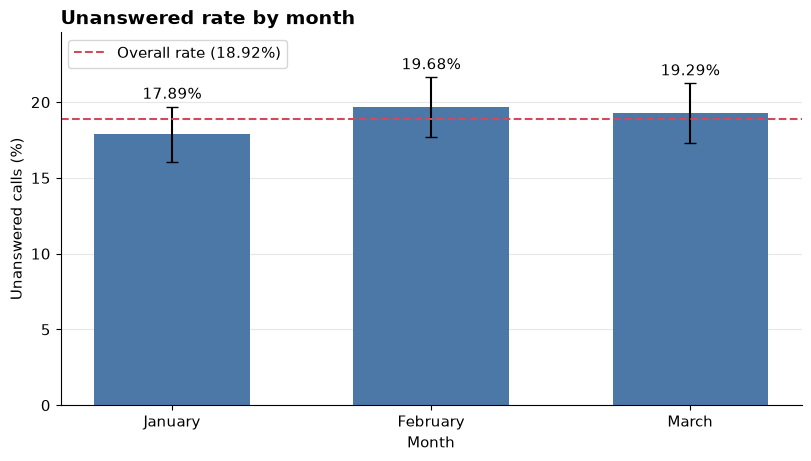

In [80]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
bars = ax.bar(
    x=df["month_name"],
    height=df["unanswered_call_pct"],
    color=BAR_COLOR_BLUE,
    width=0.6,
    yerr=2*se,
    capsize=4
)
labels = [f"{v:.2f}%" for v in df["unanswered_call_pct"]]
ax.bar_label(bars, labels=labels, padding=3)
ax.axhline(
    overall_rate,
    color=REF_LINE_RED,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate ({overall_rate:.2f}%)",
)
ax.set_ylim(0, df["unanswered_call_pct"].max() * 1.25)
ax.set_title("Unanswered rate by month")
ax.set_xlabel("Month")
ax.set_ylabel("Unanswered calls (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

chart_name = filename.replace(".sql", ".png", 1).replace("kpi_", "")
fig.savefig(charts_dir / chart_name, dpi=200, bbox_inches="tight")
plt.show()


##### Observations

1. January’s unanswered rate (17.89%) is below the overall rate of 18.92%, while February (19.68%) and March (19.29%) are above it. However, each month’s range of plausible values (about ±2 percentage points) includes the overall rate, so these differences are within what chance alone could produce.

#### By Hour

In [81]:
filename = sql_results["unanswered_rate_hour"]["filename"]
sql_query = sql_results["unanswered_rate_hour"]["sql_query"]
df = sql_results["unanswered_rate_hour"]["dataframe"]
overall_rate = df["unanswered_call_cnt"].sum() / df["total_call_cnt"].sum() * 100
p = df["unanswered_call_pct"] / 100
n = df["total_call_cnt"]
se = ((p * (1-p) / n) ** 0.5) * 100
print(filename)
print(sql_query)
display(
    df.assign(diff_from_overall_pp=(df["unanswered_call_pct"] - overall_rate).round(2))
)

kpi_unanswered_pct_by_hour.sql
-- KPI: Unanswered call % by hour of day
-- Purpose: Identify peak hours for unanswered calls 
--          (unanswered calls / total calls arriving in that hour).
-- Source: vw_call_records_enriched (see 00_create_view.sql)
-- Output: Ordered chronologically by hour for direct plotting.
-- Scope Note: The 18:00 hour is excluded. It contains only 14 calls across the
--             entire dataset (vs. ~500–600 calls/hour during standard operational hours),
--             indicating post-shift spillover rather than a fully staffed hour
--             (see 02_exploratory_checks.ipynb).
SELECT
    hour_of_day,
    COUNT(*) FILTER(WHERE answered = 'no') AS unanswered_call_cnt,
    COUNT(*) AS total_call_cnt,
    ROUND(
        (CAST(COUNT(*) FILTER(WHERE answered = 'no') AS REAL) / COUNT(*))
        * 100
    , 2) AS unanswered_call_pct
FROM
    vw_call_records_enriched
WHERE
    hour_of_day <> '18'
GROUP BY
    hour_of_day
ORDER BY
    hour_of_day;


,hour_of_day,unanswered_call_cnt,total_call_cnt,unanswered_call_pct,diff_from_overall_pp
0,09,111,547,20.29,1.36
1,10,97,529,18.34,-0.59
2,11,109,590,18.47,-0.46
3,12,116,547,21.21,2.28
4,13,110,594,18.52,-0.41
5,14,93,499,18.64,-0.29
6,15,96,531,18.08,-0.85
7,16,104,566,18.37,-0.56
8,17,108,583,18.52,-0.41


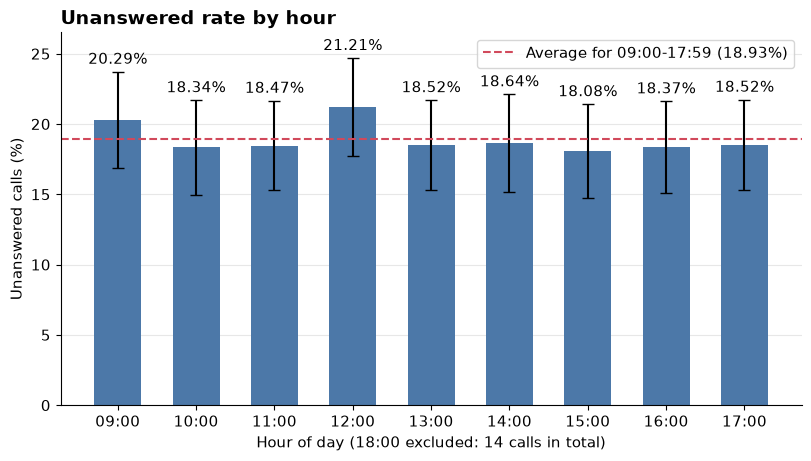

In [82]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
bars = ax.bar(
    x=df["hour_of_day"] + ":00",
    height=df["unanswered_call_pct"],
    color=BAR_COLOR_BLUE,
    width=0.6,
    yerr=2*se,
    capsize=4
)
labels = [f"{v:.2f}%" for v in df["unanswered_call_pct"]]
ax.bar_label(bars, labels=labels, padding=3)
ax.axhline(
    overall_rate,
    color=REF_LINE_RED,
    linestyle="--",
    linewidth=1.5,
    label=f"Average for 09:00-17:59 ({overall_rate:.2f}%)",
)
ax.set_ylim(0, df["unanswered_call_pct"].max() * 1.25)
ax.set_title("Unanswered rate by hour")
ax.set_xlabel("Hour of day (18:00 excluded: 14 calls in total)")
ax.set_ylabel("Unanswered calls (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

chart_name = filename.replace(".sql", ".png", 1).replace("kpi_", "")
fig.savefig(charts_dir / chart_name, dpi=200, bbox_inches="tight")
plt.show()


##### Observations

1. Only the 09:00 and 12:00 hours are above the 09:00–17:59 average of 18.93%, at 20.29% and 21.21% respectively. Every other hour is below it. However, every hour’s range of plausible values (about ±3.2 to ±3.5 percentage points) includes the average, so none of the hourly differences can be told apart from chance.

#### By Agent

In [83]:
filename = sql_results["unanswered_rate_agnt"]["filename"]
sql_query = sql_results["unanswered_rate_agnt"]["sql_query"]
df = sql_results["unanswered_rate_agnt"]["dataframe"]
overall_rate = df["unanswered_call_cnt"].sum() / df["assigned_call_cnt"].sum() * 100
p = df["unanswered_call_pct"] / 100
n = df["assigned_call_cnt"]
se = ((p * (1-p) / n) ** 0.5) * 100
print(filename)
print(sql_query)
display(
    df.assign(diff_from_overall_pp=(df["unanswered_call_pct"] - overall_rate).round(2))
)

kpi_unanswered_pct_by_agnt.sql
-- KPI: Unanswered call % by agent
-- Purpose: Compare the unanswered call % by each agent
--          (unanswered calls / calls assigned to that agent)
-- Scope Note: Includes all hours (including the 18:00 hour as the exclusion only 
--             applies to hourly KPIs).
-- Source: vw_call_records_enriched (see 00_create_view.sql)
-- Output: Ordered alphabetically by agent so tables and charts can line up across
--         metrics.

SELECT
    agent,
    COUNT(*) FILTER(WHERE answered = 'no') AS unanswered_call_cnt,
    COUNT(*) AS assigned_call_cnt,
    ROUND(
        (CAST(COUNT(*) FILTER(WHERE answered = 'no') AS REAL) / COUNT(*))
        * 100
    , 2) AS unanswered_call_pct
FROM
    vw_call_records_enriched
GROUP BY
    agent
ORDER BY
    agent;


,agent,unanswered_call_cnt,assigned_call_cnt,unanswered_call_pct,diff_from_overall_pp
0,Becky,114,631,18.07,-0.85
1,Dan,110,633,17.38,-1.54
2,Diane,132,633,20.85,1.93
3,Greg,122,624,19.55,0.63
4,Jim,130,666,19.52,0.60
5,Joe,109,593,18.38,-0.54
6,Martha,124,638,19.44,0.52
7,Stewart,105,582,18.04,-0.88


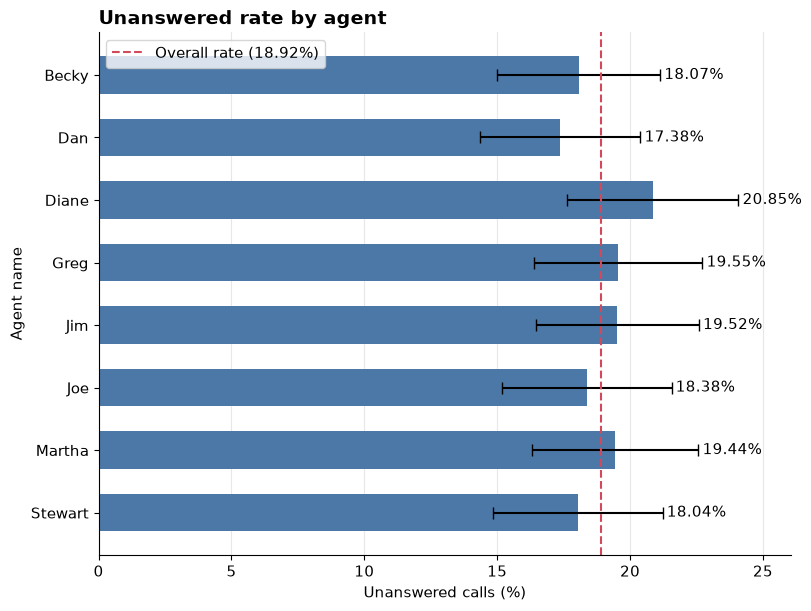

In [84]:
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
bars = ax.barh(
    y=df["agent"],
    width=df["unanswered_call_pct"],
    color=BAR_COLOR_BLUE,
    height=0.6,
    xerr=2*se,
    capsize=4
)
labels = [f"{v:.2f}%" for v in df["unanswered_call_pct"]]
ax.bar_label(bars, labels=labels, padding=3)
ax.axvline(
    overall_rate,
    color=REF_LINE_RED,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate ({overall_rate:.2f}%)",
)
ax.set_xlim(0, df["unanswered_call_pct"].max() * 1.25)
ax.set_title("Unanswered rate by agent")
ax.set_ylabel("Agent name")
ax.set_xlabel("Unanswered calls (%)")
ax.invert_yaxis()
ax.legend()
ax.grid(axis="x", alpha=0.3)

chart_name = filename.replace(".sql", ".png", 1).replace("kpi_", "")
fig.savefig(charts_dir / chart_name, dpi=200, bbox_inches="tight")
plt.show()


##### Observations

1. Four agents (Becky, Dan, Joe and Stewart) have an unanswered rate below the overall rate of 18.92%, and four (Diane, Greg, Jim and Martha) have a rate above it. However, every agent’s range of plausible values (about ±3.0 to ±3.2 percentage points) includes the overall rate, so none of these differences can be told apart from chance.
2. Of the calls assigned to Diane, 20.85% went unanswered, the highest of the eight agents, against 17.38% for Dan, the lowest. The 3.47-point gap between them is within what chance can produce, and their ranges overlap.

#### By Department

In [85]:
filename = sql_results["unanswered_rate_dept"]["filename"]
sql_query = sql_results["unanswered_rate_dept"]["sql_query"]
df = sql_results["unanswered_rate_dept"]["dataframe"]
overall_rate = df["unanswered_call_cnt"].sum() / df["total_call_cnt"].sum() * 100
p = df["unanswered_call_pct"] / 100
n = df["total_call_cnt"]
se = ((p * (1-p) / n) ** 0.5) * 100
print(filename)
print(sql_query)
display(
    df.assign(diff_from_overall_pp=(df["unanswered_call_pct"] - overall_rate).round(2))
)

kpi_unanswered_pct_by_dept.sql
-- KPI: Unanswered call % by department
-- Purpose: Compare the unanswered call % by each department
--          (unanswered calls / calls pertaining to that department)
-- Scope Note: Includes all hours (including the 18:00 hour as the exclusion only 
--             applies to hourly KPIs).
-- Source: vw_call_records_enriched (see 00_create_view.sql)
-- Output: Ordered alphabetically by department so tables and charts can line up across
--         metrics.

SELECT
    department,
    COUNT(*) FILTER(WHERE answered = 'no') AS unanswered_call_cnt,
    COUNT(*) AS total_call_cnt,
    ROUND(
        (CAST(COUNT(*) FILTER(WHERE answered = 'no') AS REAL) / COUNT(*))
        * 100
    , 2) AS unanswered_call_pct
FROM
    vw_call_records_enriched
GROUP BY
    department
ORDER BY
    department;


,department,unanswered_call_cnt,total_call_cnt,unanswered_call_pct,diff_from_overall_pp
0,Air Conditioner,214,1019,21.00,2.08
1,Fridge,181,976,18.55,-0.37
2,Television,175,1022,17.12,-1.80
3,Toaster,189,1007,18.77,-0.15
4,Washing Machine,187,976,19.16,0.24


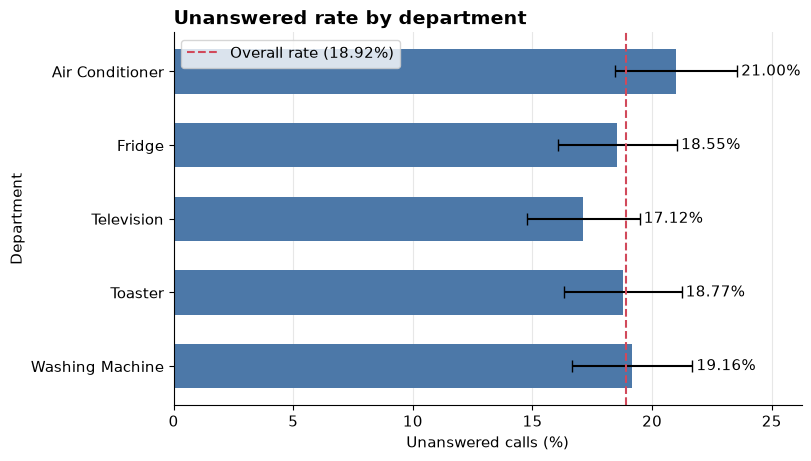

In [86]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
bars = ax.barh(
    y=df["department"],
    width=df["unanswered_call_pct"],
    color=BAR_COLOR_BLUE,
    height=0.6,
    xerr=2*se,
    capsize=4
)
labels = [f"{v:.2f}%" for v in df["unanswered_call_pct"]]
ax.bar_label(bars, labels=labels, padding=3)
ax.axvline(
    overall_rate,
    color=REF_LINE_RED,
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate ({overall_rate:.2f}%)",
)
ax.set_xlim(0, df["unanswered_call_pct"].max() * 1.25)
ax.set_title("Unanswered rate by department")
ax.set_ylabel("Department")
ax.set_xlabel("Unanswered calls (%)")
ax.invert_yaxis()
ax.legend()
ax.grid(axis="x", alpha=0.3)

chart_name = filename.replace(".sql", ".png", 1).replace("kpi_", "")
fig.savefig(charts_dir / chart_name, dpi=200, bbox_inches="tight")
plt.show()


##### Observations

1. Only Air Conditioner (21.00%) and Washing Machine (19.16%) have an unanswered rate above the overall rate of 18.92%. The other three departments are below it. However, every department’s range of plausible values (about ±2.4 to ±2.6 percentage points) includes the overall rate, so none of these differences can be told apart from chance.
2. Calls pertaining to Air Conditioner have the highest unanswered rate (21.00%) and Television the lowest (17.12%), a gap of 3.88 percentage points. With five departments there is always a highest and a lowest, and the Air Conditioner range only just includes the overall rate, so this gap is not strong evidence of a real difference.